# 2.2. Practica. Análisis, implementación y prueba de un modelo de lógica difusa Mamdani para comprender el funcionamiento de IA aplicada al IOT

## Propósito de la actividad

Diseñar un modelo de lógica difusa Mamdani para comprender el funcionamiento de Inteligencia Artificial aplicada al IOT.

## Instrucciones.

El alumno deberá analizar, implementar y evaluar un modelo de lógica difusa Mamdani para comprender el funcionamiento de Inteligencia Artificial aplicada al IOT.

## Datos generales

**Alumno:** Marco Sebastián Hernández Parada

**Caso práctico:** Control inteligente de la velocidad de un ventilador a partir de la temperatura y la humedad, mediante un controlador difuso Mamdani ejecutado en un ESP32.

**Desarrollo del modelo:** Python 3 (NumPy y Matplotlib) en este notebook.

**Implementación IoT:** Arduino (C++) sobre ESP32, simulado en Wokwi (https://wokwi.com).

**Enlace al proyecto en Wokwi:** https://wokwi.com/projects/479235737030424577

## 1. Análisis del caso práctico

### 1.1 Planteamiento del problema

En la Práctica 1.2 se construyó un dispositivo IoT que encendía un ventilador cuando la temperatura superaba un umbral fijo. Ese control de tipo encendido/apagado tiene dos problemas:

- **Es brusco:** a 29.9 °C el ventilador está apagado y a 30.1 °C trabaja al 100 %, aunque la diferencia entre ambas situaciones es mínima. Cerca del umbral el actuador conmuta constantemente, lo que desgasta el equipo y desperdicia energía.
- **Ignora el contexto:** la sensación térmica y el riesgo para equipos o productos no dependen solo de la temperatura; con humedad alta, la misma temperatura exige más ventilación.

Una persona que regula un ventilador no razona con umbrales exactos, sino con reglas como *"si hace calor y está húmedo, sube mucho el ventilador"*. La **lógica difusa** permite programar ese conocimiento expresado en palabras, y el **modelo de inferencia Mamdani** lo convierte en una salida numérica continua (velocidad de 0 a 100 %) que varía suavemente con las entradas.

### 1.2 Objetivos

- Analizar el funcionamiento del modelo de inferencia difusa Mamdani en cada una de sus etapas.
- Diseñar un controlador difuso con dos entradas (temperatura y humedad) y una salida (velocidad del ventilador).
- Implementar el modelo en Python sin librerías especializadas, para que cada operación sea visible y fácil de trasladar a un microcontrolador.
- Verificar el modelo con un seguimiento manual (code tracing) de un ejemplo, comparando los cálculos a mano con los del programa.
- Convertir la implementación a código Arduino y ejecutarla en un ESP32 simulado en Wokwi, como ejemplo de IA aplicada al IoT.
- Evaluar el comportamiento del controlador con casos de prueba y su superficie de control.

### 1.3 Fundamentos de la lógica difusa

La lógica clásica asigna a cada elemento un valor de verdad 0 o 1: una temperatura de 29.9 °C "no es caliente" y una de 30.1 °C "sí lo es". La lógica difusa, propuesta por Lotfi A. Zadeh en 1965, permite **grados de pertenencia** intermedios en el intervalo $[0, 1]$.

- **Universo de discurso:** rango de valores que puede tomar una variable. Por ejemplo, la temperatura entre 0 y 50 °C.
- **Conjunto difuso:** conjunto $A$ definido por una **función de pertenencia** $\mu_A(x) \in [0,1]$, que indica en qué grado el valor $x$ pertenece a $A$. Por ejemplo, $\mu_{Caliente}(29) = 0.4$ se lee "29 °C es caliente en grado 0.4".
- **Variable lingüística:** variable cuyos valores son palabras (etiquetas) asociadas a conjuntos difusos. La temperatura puede valer *Fría*, *Templada* o *Caliente*.
- **Funciones de pertenencia trapezoidales:** se definen con cuatro parámetros $a \le b \le c \le d$:

$$
\mu(x; a,b,c,d) =
\begin{cases}
0 & x < a \text{ o } x > d \\
\dfrac{x-a}{b-a} & a \le x < b \\
1 & b \le x \le c \\
\dfrac{d-x}{d-c} & c < x \le d
\end{cases}
$$

  Una función **triangular** es el caso particular $b = c$, y los "hombros" en los extremos del universo se obtienen con $a = b$ o $c = d$.

- **Operadores difusos:** generalizan las operaciones lógicas. Los más usados, y los que emplea el modelo Mamdani clásico, son:

| Operación | Definición | Uso en Mamdani |
|---|---|---|
| Intersección (AND) | $\mu_{A \cap B}(x) = \min(\mu_A(x), \mu_B(x))$ | Combinar los antecedentes de una regla e implicación |
| Unión (OR) | $\mu_{A \cup B}(x) = \max(\mu_A(x), \mu_B(x))$ | Agregar las salidas de todas las reglas |
| Complemento (NOT) | $\mu_{\bar A}(x) = 1 - \mu_A(x)$ | No se utiliza en este diseño |

- **Regla difusa:** proposición del tipo *SI* $x$ *es* $A$ *Y* $y$ *es* $B$ *ENTONCES* $z$ *es* $C$. La parte *SI* es el **antecedente** y la parte *ENTONCES* es el **consecuente**.

### 1.4 El modelo de inferencia Mamdani

Mamdani y Assilian (1975) presentaron el primer controlador difuso, que regulaba una máquina de vapor usando reglas escritas por operadores humanos. Su característica principal es que **tanto los antecedentes como los consecuentes de las reglas son conjuntos difusos**, por lo que el resultado de la inferencia también es un conjunto difuso que al final se convierte en un número. Esto lo hace muy interpretable: cada regla se puede leer en lenguaje natural.

El proceso tiene cuatro etapas:

**Etapa 1. Fuzzificación.** Cada entrada numérica (*crisp*) se evalúa en todas las funciones de pertenencia de su variable. El resultado es un vector de grados de pertenencia. Por ejemplo, para $T = 29$ °C se obtiene $\mu_{Fria} = 0$, $\mu_{Templada} = 0.6$ y $\mu_{Caliente} = 0.4$: la misma lectura pertenece parcialmente a dos conjuntos.

**Etapa 2. Evaluación de las reglas (fuerza de disparo).** Para cada regla se calcula en qué grado se cumple su antecedente. Con el operador AND como mínimo:

$$
w_r = \min\big(\mu_{A_r}(T),\ \mu_{B_r}(H)\big)
$$

Una regla con $w_r = 0$ no participa; una con $w_r = 1$ se cumple por completo.

**Etapa 3. Implicación y agregación.** La implicación de Mamdani **recorta** (trunca) el conjunto consecuente de cada regla a la altura de su fuerza de disparo:

$$
\mu'_r(z) = \min\big(w_r,\ \mu_{C_r}(z)\big)
$$

Después, todos los conjuntos recortados se **agregan** con el máximo en cada punto $z$ del universo de salida, formando un único conjunto difuso:

$$
\mu_{agr}(z) = \max_{r}\ \mu'_r(z)
$$

Como $\max_r \min(w_r, \mu_C(z)) = \min(\max_r w_r, \mu_C(z))$ cuando varias reglas comparten el mismo consecuente $C$, en la implementación primero se toma la fuerza máxima de las reglas que apuntan a cada conjunto de salida (su **activación**) y luego se recorta cada conjunto una sola vez. El resultado es idéntico y requiere menos operaciones, lo que es útil en un microcontrolador.

**Etapa 4. Defuzzificación.** El conjunto agregado se convierte en un valor numérico. El método más usado es el **centroide** (centro de gravedad), que calcula el punto de equilibrio del área bajo $\mu_{agr}$:

$$
z^* = \frac{\int z\,\mu_{agr}(z)\,dz}{\int \mu_{agr}(z)\,dz} \;\approx\; \frac{\sum_i z_i\,\mu_{agr}(z_i)}{\sum_i \mu_{agr}(z_i)}
$$

La forma discreta (derecha) es la que se programa: se recorre el universo de salida en pasos fijos (aquí 0.5 %, es decir 201 puntos de 0 a 100).

**Resumen del flujo:**

1. Lectura del sensor: $T$ y $H$ (valores numéricos).
2. Fuzzificación: grados $\mu$ de cada etiqueta lingüística.
3. Evaluación de reglas: fuerza $w_r$ de cada regla con $\min$.
4. Implicación: recorte de cada consecuente a la altura $w_r$.
5. Agregación: unión con $\max$ de todos los recortes.
6. Defuzzificación: centroide, que da la velocidad del ventilador en %.

**Mamdani frente a Sugeno.** En el modelo Takagi-Sugeno el consecuente de cada regla es una función (por ejemplo una constante $z = 70$) y la salida es un promedio ponderado de esas funciones, sin defuzzificación por áreas. Sugeno es más ligero computacionalmente, pero Mamdani es más intuitivo porque las salidas también se describen con palabras ("velocidad alta"), y por ello es el modelo pedido en esta práctica.

### 1.5 Relación con la Inteligencia Artificial y el IoT

La lógica difusa es una técnica de IA simbólica: representa el **conocimiento experto** mediante reglas lingüísticas y realiza **razonamiento aproximado** con información imprecisa, como lo haría una persona. A diferencia de una red neuronal, no requiere datos de entrenamiento y cada decisión es explicable regla por regla.

En IoT, este tipo de modelo es adecuado para ejecutarse **en el borde** (*edge AI*), es decir, en el propio dispositivo:

- El cálculo es pequeño (nueve reglas y 201 puntos de salida), por lo que cabe en un microcontrolador como el ESP32 sin depender de la nube.
- El dispositivo reacciona de inmediato aunque se pierda la conexión a internet.
- La nube recibe no solo las mediciones, sino también la decisión tomada y el grado de activación de cada conjunto de salida, lo que permite supervisar el razonamiento del dispositivo a distancia (telemetría por MQTT).

### 1.6 Diseño del sistema difuso

**Variables de entrada y salida**

| Variable | Tipo | Universo | Sensor o actuador |
|---|---|---|---|
| Temperatura ($T$) | Entrada | 0 a 50 °C | DHT22 |
| Humedad relativa ($H$) | Entrada | 0 a 100 % | DHT22 |
| Velocidad del ventilador ($V$) | Salida | 0 a 100 % | LED azul controlado por PWM (simula el ventilador) |

**Conjuntos difusos** (parámetros $a, b, c, d$ de la función trapezoidal)

| Variable | Etiqueta | Forma | $a$ | $b$ | $c$ | $d$ |
|---|---|---|---|---|---|---|
| Temperatura | Fría | Trapecio (hombro izquierdo) | 0 | 0 | 10 | 20 |
| Temperatura | Templada | Trapecio | 10 | 20 | 25 | 35 |
| Temperatura | Caliente | Trapecio (hombro derecho) | 25 | 35 | 50 | 50 |
| Humedad | Baja | Trapecio (hombro izquierdo) | 0 | 0 | 20 | 50 |
| Humedad | Media | Triángulo | 20 | 50 | 50 | 80 |
| Humedad | Alta | Trapecio (hombro derecho) | 50 | 80 | 100 | 100 |
| Velocidad | Baja | Triángulo | 0 | 0 | 0 | 50 |
| Velocidad | Media | Triángulo | 25 | 50 | 50 | 75 |
| Velocidad | Alta | Triángulo | 50 | 100 | 100 | 100 |

Los conjuntos de cada entrada se traslapan de forma que, en cualquier punto, los grados de pertenencia suman 1 (partición de Ruspini). Así toda lectura del sensor activa al menos una regla y la transición entre etiquetas es gradual.

**Base de reglas**

Se definieron 9 reglas, una por cada combinación de etiquetas de entrada ($3 \times 3$). La tabla se lee como *SI T es (fila) Y H es (columna) ENTONCES V es (celda)*:

| T \ H | Baja | Media | Alta |
|---|---|---|---|
| **Fría** | Baja (R1) | Baja (R2) | Media (R3) |
| **Templada** | Baja (R4) | Media (R5) | Alta (R6) |
| **Caliente** | Media (R7) | Alta (R8) | Alta (R9) |

El criterio es que la velocidad crece con la temperatura y con la humedad. Con frío y humedad alta (R3) se usa velocidad media para evitar condensación, y con calor y aire seco (R7) también media, porque el aire seco facilita la disipación del calor.

**Métodos de inferencia:** AND = mínimo, implicación = mínimo (recorte), agregación = máximo, defuzzificación = centroide.

## 2. Implementación del modelo en Python

El modelo se programa solo con estructuras básicas de Python (funciones, diccionarios, listas y ciclos). No se usan librerías de lógica difusa como scikit-fuzzy por dos razones: cada etapa del método Mamdani queda explícita en el código y la traducción al lenguaje de Arduino es casi línea por línea. NumPy y Matplotlib se usan únicamente para las gráficas y la evaluación.

### 2.1 Librerías

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Colores para las tres etiquetas de cada variable (baja, media, alta)
COLORES = ["#2a78d6", "#eb6834", "#1baf7a"]
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

### 2.2 Función de pertenencia

Una sola función trapezoidal cubre los tres tipos de conjuntos del diseño: trapecios, triángulos ($b = c$) y hombros ($a = b$ o $c = d$). El orden de las comparaciones evita divisiones entre cero en los casos degenerados.

In [2]:
def trapmf(x, a, b, c, d):
    """Grado de pertenencia de x a un conjunto trapezoidal (a, b, c, d)."""
    if x < a or x > d:
        return 0.0
    if b <= x <= c:
        return 1.0
    if x < b:
        return (x - a) / (b - a)
    return (d - x) / (d - c)

### 2.3 Variables lingüísticas

Cada variable es un diccionario que asocia una etiqueta con los parámetros de su función de pertenencia. El universo de salida se discretiza con un paso de 0.5 %.

In [3]:
TEMPERATURA = {
    "Fria": (0, 0, 10, 20),
    "Templada": (10, 20, 25, 35),
    "Caliente": (25, 35, 50, 50),
}
HUMEDAD = {
    "Baja": (0, 0, 20, 50),
    "Media": (20, 50, 50, 80),
    "Alta": (50, 80, 100, 100),
}
VELOCIDAD = {
    "Baja": (0, 0, 0, 50),
    "Media": (25, 50, 50, 75),
    "Alta": (50, 100, 100, 100),
}

RANGO_T = (0, 50)
RANGO_H = (0, 100)
PASO = 0.5
Z = [i * PASO for i in range(201)]  # universo discreto de la salida: 0, 0.5, ..., 100

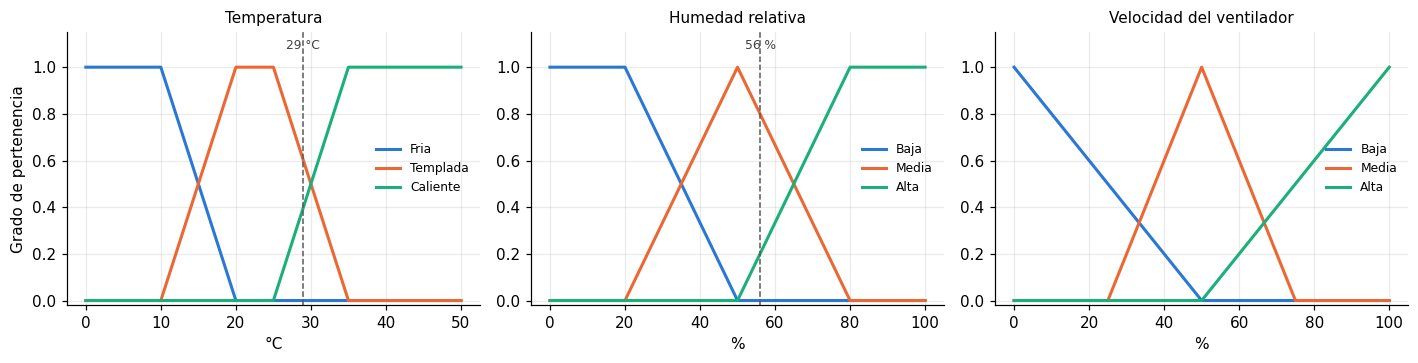

In [4]:
def graficar_variable(ax, variable, universo, titulo, unidad, marca=None):
    xs = np.linspace(*universo, 501)
    for color, (nombre, p) in zip(COLORES, variable.items()):
        ys = [trapmf(x, *p) for x in xs]
        ax.plot(xs, ys, color=color, lw=2, label=nombre)
    if marca is not None:
        ax.axvline(marca, color="0.35", lw=1, ls="--")
        ax.text(marca, 1.08, f"{marca} {unidad}", ha="center", fontsize=8, color="0.25")
    ax.set_title(titulo, fontsize=10)
    ax.set_xlabel(unidad)
    ax.set_ylim(-0.02, 1.15)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8, frameon=False, loc="center right")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
graficar_variable(axes[0], TEMPERATURA, RANGO_T, "Temperatura", "°C", marca=29)
graficar_variable(axes[1], HUMEDAD, RANGO_H, "Humedad relativa", "%", marca=56)
graficar_variable(axes[2], VELOCIDAD, (0, 100), "Velocidad del ventilador", "%")
axes[0].set_ylabel("Grado de pertenencia")
plt.tight_layout()
plt.show()

**Figura 1.** Funciones de pertenencia de las tres variables. Las líneas punteadas marcan las entradas del ejemplo que se sigue a mano en la sección 3 ($T$ = 29 °C, $H$ = 56 %).

### 2.4 Base de reglas

Las reglas se guardan como una matriz: la fila es la etiqueta de temperatura, la columna la de humedad y la celda el consecuente. Esta representación se copia directamente al microcontrolador.

In [5]:
REGLAS = [
    # H: Baja   Media    Alta
    ["Baja",  "Baja",  "Media"],  # T: Fria
    ["Baja",  "Media", "Alta"],   # T: Templada
    ["Media", "Alta",  "Alta"],   # T: Caliente
]

for i, et in enumerate(TEMPERATURA):
    for j, eh in enumerate(HUMEDAD):
        n = 3 * i + j + 1
        print(f"R{n}: SI T es {et:<8} Y H es {eh:<5} ENTONCES V es {REGLAS[i][j]}")

R1: SI T es Fria     Y H es Baja  ENTONCES V es Baja
R2: SI T es Fria     Y H es Media ENTONCES V es Baja
R3: SI T es Fria     Y H es Alta  ENTONCES V es Media
R4: SI T es Templada Y H es Baja  ENTONCES V es Baja
R5: SI T es Templada Y H es Media ENTONCES V es Media
R6: SI T es Templada Y H es Alta  ENTONCES V es Alta
R7: SI T es Caliente Y H es Baja  ENTONCES V es Media
R8: SI T es Caliente Y H es Media ENTONCES V es Alta
R9: SI T es Caliente Y H es Alta  ENTONCES V es Alta


### 2.5 Motor de inferencia Mamdani

La función `mamdani` ejecuta las cuatro etapas descritas en la sección 1.4 y devuelve, además de la velocidad, todos los resultados intermedios para poder revisarlos en el seguimiento manual.

In [ ]:
def fuzzificar(x, variable):
    """Etapa 1: grado de pertenencia de x a cada etiqueta de la variable."""
    return {nombre: trapmf(x, *p) for nombre, p in variable.items()}


def mamdani(temp, hum):
    # Las lecturas fuera del universo se saturan a sus limites
    temp = min(max(temp, RANGO_T[0]), RANGO_T[1])
    hum = min(max(hum, RANGO_H[0]), RANGO_H[1])

    # 1. Fuzzificación
    mu_t = fuzzificar(temp, TEMPERATURA)
    mu_h = fuzzificar(hum, HUMEDAD)

    # 2. Evaluación de reglas (AND = min) y activacion de cada consecuente (max)
    disparos = []
    activacion = {nombre: 0.0 for nombre in VELOCIDAD}
    for i, et in enumerate(TEMPERATURA):
        for j, eh in enumerate(HUMEDAD):
            consecuente = REGLAS[i][j]
            fuerza = min(mu_t[et], mu_h[eh])
            disparos.append((et, eh, consecuente, fuerza))
            activacion[consecuente] = max(activacion[consecuente], fuerza)

    # 3. Implicación (min = recorte) y agregación (max) en cada punto del universo
    agregada = []
    for z in Z:
        mu = 0.0
        for nombre, p in VELOCIDAD.items():
            mu = max(mu, min(activacion[nombre], trapmf(z, *p)))
        agregada.append(mu)

    # 4. Defuzzificación por centroide (forma discreta)
    num = sum(z * mu for z, mu in zip(Z, agregada))
    den = sum(agregada)
    velocidad = num / den if den > 0 else 0.0

    return {"mu_t": mu_t, "mu_h": mu_h, "disparos": disparos, "activacion": activacion,
            "agregada": agregada, "num": num, "den": den, "velocidad": velocidad}

## 3. Seguimiento manual del modelo (code tracing)

Para comprobar que se entiende el funcionamiento del modelo, se resuelve a mano un caso y después se compara con la salida del programa. La entrada elegida es una lectura típica de un cuarto cálido y algo húmedo:

$$T = 29\ \text{°C}, \qquad H = 56\ \%$$

Se eligió porque activa dos etiquetas en cada entrada y hace que **varias reglas apunten al mismo consecuente**, lo que permite observar la agregación con el máximo.

### 3.1 Etapa 1: fuzzificación

En la función `mamdani` corresponde a las líneas `mu_t = fuzzificar(temp, TEMPERATURA)` y `mu_h = fuzzificar(hum, HUMEDAD)`. Primero se verifica que las entradas estén dentro del universo: 29 está en $[0, 50]$ y 56 en $[0, 100]$, así que no se saturan.

**Temperatura, $T = 29$:**

| Etiqueta | $(a,b,c,d)$ | Caso de `trapmf` | Cálculo | $\mu$ |
|---|---|---|---|---|
| Fría | (0, 0, 10, 20) | $x > d$ (29 > 20) | regresa 0 | **0.0** |
| Templada | (10, 20, 25, 35) | $c < x \le d$ (pendiente de bajada) | $(35 - 29)/(35 - 25) = 6/10$ | **0.6** |
| Caliente | (25, 35, 50, 50) | $a \le x < b$ (pendiente de subida) | $(29 - 25)/(35 - 25) = 4/10$ | **0.4** |

**Humedad, $H = 56$:**

| Etiqueta | $(a,b,c,d)$ | Caso de `trapmf` | Cálculo | $\mu$ |
|---|---|---|---|---|
| Baja | (0, 0, 20, 50) | $x > d$ (56 > 50) | regresa 0 | **0.0** |
| Media | (20, 50, 50, 80) | $c < x \le d$ | $(80 - 56)/(80 - 50) = 24/30$ | **0.8** |
| Alta | (50, 80, 100, 100) | $a \le x < b$ | $(56 - 50)/(80 - 50) = 6/30$ | **0.2** |

Interpretación: 29 °C es "templada" en grado 0.6 y "caliente" en grado 0.4; la humedad de 56 % es principalmente "media" (0.8) y un poco "alta" (0.2). En ambos casos los grados suman 1, como se esperaba por la partición de Ruspini.

### 3.2 Etapa 2: evaluación de las reglas

En el código es el doble ciclo `for i, et ... for j, eh ...`, que calcula `fuerza = min(mu_t[et], mu_h[eh])` para cada regla y actualiza `activacion[consecuente] = max(activacion[consecuente], fuerza)`.

| Regla | Antecedente | $\min(\mu_T, \mu_H)$ | $w_r$ | Consecuente | `activacion` después de la regla (Baja, Media, Alta) |
|---|---|---|---|---|---|
| R1 | Fría Y Baja | $\min(0.0, 0.0)$ | 0.0 | Baja | (0.0, 0.0, 0.0) |
| R2 | Fría Y Media | $\min(0.0, 0.8)$ | 0.0 | Baja | (0.0, 0.0, 0.0) |
| R3 | Fría Y Alta | $\min(0.0, 0.2)$ | 0.0 | Media | (0.0, 0.0, 0.0) |
| R4 | Templada Y Baja | $\min(0.6, 0.0)$ | 0.0 | Baja | (0.0, 0.0, 0.0) |
| R5 | Templada Y Media | $\min(0.6, 0.8)$ | **0.6** | Media | (0.0, **0.6**, 0.0) |
| R6 | Templada Y Alta | $\min(0.6, 0.2)$ | **0.2** | Alta | (0.0, 0.6, **0.2**) |
| R7 | Caliente Y Baja | $\min(0.4, 0.0)$ | 0.0 | Media | (0.0, 0.6, 0.2) |
| R8 | Caliente Y Media | $\min(0.4, 0.8)$ | **0.4** | Alta | (0.0, 0.6, **0.4**) |
| R9 | Caliente Y Alta | $\min(0.4, 0.2)$ | **0.2** | Alta | (0.0, 0.6, 0.4) |

Se disparan cuatro reglas (R5, R6, R8 y R9). Tres de ellas concluyen "velocidad alta" con fuerzas 0.2, 0.4 y 0.2; al unirlas con el máximo prevalece la más fuerte, de modo que:

$$\text{activación}(Baja) = 0, \qquad \text{activación}(Media) = 0.6, \qquad \text{activación}(Alta) = \max(0.2, 0.4, 0.2) = 0.4$$

Ninguna regla con consecuente "Baja" se disparó, por lo que ese conjunto no aporta área a la salida.

### 3.3 Etapa 3: implicación y agregación

En el código es el ciclo `for z in Z`, que en cada punto calcula `max(mu, min(activacion[nombre], trapmf(z, *p)))`.

- **Media** (triángulo 25, 50, 75) se recorta a 0.6. La pendiente de subida $(z-25)/25$ alcanza 0.6 en $z = 25 + 0.6 \cdot 25 = 40$ y la de bajada $(75-z)/25$ vale 0.6 en $z = 75 - 0.6 \cdot 25 = 60$. El resultado es un trapecio (25, 40, 60, 75) de altura 0.6.
- **Alta** (triángulo 50, 100, 100) se recorta a 0.4. La pendiente $(z-50)/50$ vale 0.4 en $z = 70$, así que queda un trapecio (50, 70, 100, 100) de altura 0.4.

Al tomar el máximo de ambos conjuntos recortados, el cruce ocurre donde la bajada de Media iguala a la subida de Alta:

$$\frac{75 - z}{25} = \frac{z - 50}{50} \;\Rightarrow\; 150 - 2z = z - 50 \;\Rightarrow\; z = \tfrac{200}{3} \approx 66.67, \quad \mu = \tfrac{1}{3} \approx 0.333$$

El conjunto agregado queda definido por tramos:

$$
\mu_{agr}(z) =
\begin{cases}
0 & 0 \le z < 25 \\
(z - 25)/25 & 25 \le z < 40 \\
0.6 & 40 \le z < 60 \\
(75 - z)/25 & 60 \le z < 66.67 \\
(z - 50)/50 & 66.67 \le z < 70 \\
0.4 & 70 \le z \le 100
\end{cases}
$$

Algunos valores puntuales para comprobar contra el programa: $\mu_{agr}(30) = 0.2$, $\mu_{agr}(50) = 0.6$, $\mu_{agr}(65) = 0.4$ (Media recortada da $(75-65)/25 = 0.4$ y Alta da $0.3$), $\mu_{agr}(90) = 0.4$.

### 3.4 Etapa 4: defuzzificación por centroide

Con la forma continua del centroide se integra cada tramo. El área es $\int \mu\,dz$ y el momento es $\int z\,\mu\,dz$:

| Tramo | $\mu_{agr}(z)$ | Forma | Área | Momento |
|---|---|---|---|---|
| [25, 40] | $(z-25)/25$ | Triángulo de base 15 y altura 0.6 | 4.5000 | 157.5000 |
| [40, 60] | 0.6 | Rectángulo de base 20 y altura 0.6 | 12.0000 | 600.0000 |
| [60, 66.67] | $(75-z)/25$ | Trapecio con alturas 0.6 y 0.333 | 3.1111 | 196.0494 |
| [66.67, 70] | $(z-50)/50$ | Trapecio con alturas 0.333 y 0.4 | 1.2222 | 83.5802 |
| [70, 100] | 0.4 | Rectángulo de base 30 y altura 0.4 | 12.0000 | 1020.0000 |
| **Total** | | | **32.8333** | **2057.1296** |

Las áreas de los tramos rectos son base por altura; las de los tramos inclinados, base por el promedio de las alturas. Para los rectángulos el momento es $h \cdot \frac{b^2 - a^2}{2}$, por ejemplo $0.6 \cdot \frac{60^2 - 40^2}{2} = 600$. En los tramos inclinados el momento se obtiene integrando; para el primero: $\int_{25}^{40} z\,\frac{z-25}{25}\,dz = \frac{1}{25}\left[\frac{z^3}{3} - \frac{25 z^2}{2}\right]_{25}^{40} = 157.5$.

$$z^* = \frac{2057.1296}{32.8333} \approx 62.65\ \%$$

El programa usa la forma discreta con 201 puntos, $z^* = \sum z_i \mu_i / \sum \mu_i$. Como la suma con paso $\Delta z = 0.5$ aproxima la integral dividida entre $\Delta z$, el denominador esperado es cercano a $32.83 / 0.5 \approx 65.67$ y el numerador a $2057.13 / 0.5 \approx 4114.3$. La pequeña diferencia entre ambos métodos se debe a la discretización (la suma incluye completos los extremos de cada tramo), y no afecta la decisión: en ambos casos el ventilador debe girar a cerca del **63 %**.

**Lectura del resultado:** la situación es mayormente "templada con humedad media" (velocidad media, 50 %), pero el componente "caliente" y la humedad alta empujan el centroide hacia la velocidad alta, por lo que el resultado queda entre ambos conjuntos, más cerca de Media porque su activación (0.6) es mayor que la de Alta (0.4).

### 3.5 Verificación con el programa

Se ejecuta `mamdani(29, 56)` y se imprimen los resultados intermedios para compararlos con el seguimiento manual.

In [ ]:
r = mamdani(29, 56)

print("Etapa 1. Fuzzificación")
print("  mu_T:", {k: round(v, 4) for k, v in r["mu_t"].items()})
print("  mu_H:", {k: round(v, 4) for k, v in r["mu_h"].items()})

print("\nEtapa 2. Fuerza de disparo de cada regla")
for n, (et, eh, cons, w) in enumerate(r["disparos"], start=1):
    marca = "  <- se dispara" if w > 0 else ""
    print(f"  R{n}: min(T {et:<8}, H {eh:<5}) = {w:.2f} -> V {cons}{marca}")
print("  Activacion:", {k: round(v, 4) for k, v in r["activacion"].items()})

print("\nEtapa 3. Conjunto agregado en puntos de control")
for z in (30, 50, 65, 90):
    print(f"  mu_agr({z}) = {r['agregada'][Z.index(z)]:.4f}")

print("\nEtapa 4. Centroide discreto")
print(f"  Suma z*mu = {r['num']:.4f}")
print(f"  Suma mu   = {r['den']:.4f}")
print(f"  Velocidad = {r['num']:.4f} / {r['den']:.4f} = {r['velocidad']:.2f} %")

Etapa 1. Fuzzificacion
  mu_T: {'Fria': 0.0, 'Templada': 0.6, 'Caliente': 0.4}
  mu_H: {'Baja': 0.0, 'Media': 0.8, 'Alta': 0.2}

Etapa 2. Fuerza de disparo de cada regla
  R1: min(T Fria    , H Baja ) = 0.00 -> V Baja
  R2: min(T Fria    , H Media) = 0.00 -> V Baja
  R3: min(T Fria    , H Alta ) = 0.00 -> V Media
  R4: min(T Templada, H Baja ) = 0.00 -> V Baja
  R5: min(T Templada, H Media) = 0.60 -> V Media  <- se dispara
  R6: min(T Templada, H Alta ) = 0.20 -> V Alta  <- se dispara
  R7: min(T Caliente, H Baja ) = 0.00 -> V Media
  R8: min(T Caliente, H Media) = 0.40 -> V Alta  <- se dispara
  R9: min(T Caliente, H Alta ) = 0.20 -> V Alta  <- se dispara
  Activacion: {'Baja': 0.0, 'Media': 0.6, 'Alta': 0.4}

Etapa 3. Conjunto agregado en puntos de control
  mu_agr(30) = 0.2000
  mu_agr(50) = 0.6000
  mu_agr(65) = 0.4000
  mu_agr(90) = 0.4000

Etapa 4. Centroide discreto
  Suma z*mu = 4134.5150
  Suma mu   = 65.8700
  Velocidad = 4134.5150 / 65.8700 = 62.77 %


In [ ]:
# Centroide continuo con una malla muy fina, para compararlo con el calculo a mano
zf = np.linspace(0, 100, 200001)
act = r["activacion"]
recortes = [np.minimum(act[n], [trapmf(z, *p) for z in zf])
            for n, p in VELOCIDAD.items()]
mu_f = np.maximum.reduce(recortes)
area = np.trapezoid(mu_f, zf)
momento = np.trapezoid(zf * mu_f, zf)
print(f"Area bajo la curva: {area:.4f}   Momento: {momento:.4f}")
print(f"Centroide continuo (integral numérica): {momento / area:.2f} %")

Area bajo la curva: 32.8333   Momento: 2057.1296
Centroide continuo (integral numerica): 62.65 %


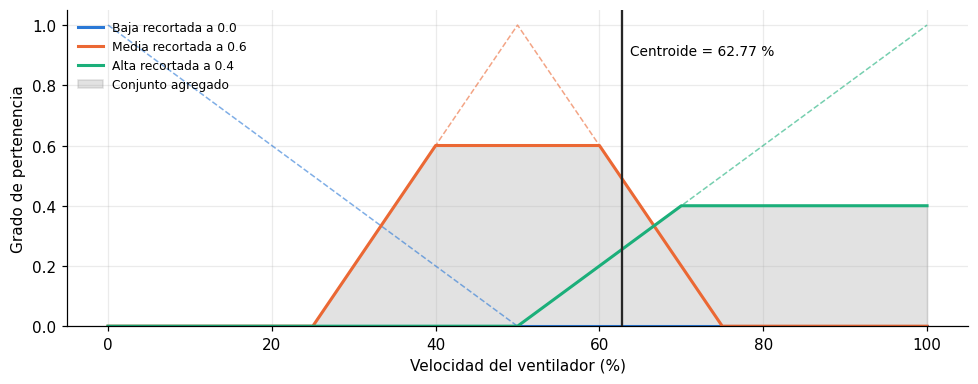

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for color, (nombre, p) in zip(COLORES, VELOCIDAD.items()):
    original = [trapmf(z, *p) for z in Z]
    recortado = [min(act[nombre], m) for m in original]
    ax.plot(Z, original, color=color, lw=1, ls="--", alpha=0.6)
    etiqueta = f"{nombre} recortada a {act[nombre]:.1f}"
    ax.plot(Z, recortado, color=color, lw=2, label=etiqueta)
ax.fill_between(Z, r["agregada"], color="0.55", alpha=0.25, label="Conjunto agregado")
ax.axvline(r["velocidad"], color="0.15", lw=1.5)
ax.text(r["velocidad"] + 1, 0.9, f"Centroide = {r['velocidad']:.2f} %", fontsize=9)
ax.set_xlabel("Velocidad del ventilador (%)")
ax.set_ylabel("Grado de pertenencia")
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.25)
ax.legend(fontsize=8, frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

**Figura 2.** Implicación, agregación y defuzzificación para $T$ = 29 °C y $H$ = 56 %. Las líneas punteadas son los conjuntos de salida originales, las continuas los conjuntos recortados por su activación, el área gris es el conjunto agregado y la línea vertical su centroide.

**Comparación del seguimiento manual con el programa**

| Etapa | Valor calculado a mano | Valor del programa | Coincide |
|---|---|---|---|
| Fuzzificación de $T$ (Fría, Templada, Caliente) | 0.0, 0.6, 0.4 | 0.0, 0.6, 0.4 | Sí |
| Fuzzificación de $H$ (Baja, Media, Alta) | 0.0, 0.8, 0.2 | 0.0, 0.8, 0.2 | Sí |
| Reglas disparadas | R5 = 0.6, R6 = 0.2, R8 = 0.4, R9 = 0.2 | R5 = 0.6, R6 = 0.2, R8 = 0.4, R9 = 0.2 | Sí |
| Activación (Baja, Media, Alta) | 0.0, 0.6, 0.4 | 0.0, 0.6, 0.4 | Sí |
| $\mu_{agr}$ en 30, 50, 65, 90 | 0.2, 0.6, 0.4, 0.4 | 0.2, 0.6, 0.4, 0.4 | Sí |
| Área y momento (continuo) | 32.8333 y 2057.1296 | ver la salida de la integral numérica | Sí |
| Centroide | 62.65 % (continuo) | 62.65 % (continuo) y 62.77 % (discreto) | Sí, la diferencia de 0.12 se debe a la discretización |

## 4. Conversión a código Arduino e implementación en Wokwi

### 4.1 Equivalencias entre Python y Arduino (C++)

El modelo se escribió en Python con la estructura que tendría en un microcontrolador, por lo que la conversión consiste en sustituir cada construcción por su equivalente en C++:

| Elemento | Python | Arduino (C++) |
|---|---|---|
| Parámetros de un conjunto | tupla `(0, 0, 10, 20)` | `struct Conjunto { const char* nombre; float a, b, c, d; }` |
| Variable lingüística | diccionario `TEMPERATURA = {...}` | arreglo constante `const Conjunto TEMPERATURA[3]` |
| Base de reglas | lista de listas con nombres | matriz `const int REGLAS[3][3]` con índices (`V_BAJA`, `V_MEDIA`, `V_ALTA`) |
| Función de pertenencia | `def trapmf(x, a, b, c, d)` | `float trapmf(float x, const Conjunto& s)`, misma lógica |
| Saturación de entradas | `min(max(temp, 0), 50)` | `constrain(temp, 0.0, 50.0)` |
| Resultado con valores intermedios | diccionario devuelto por `mamdani` | `struct Resultado` con `muT`, `muH`, `activacion` y `velocidad` |
| Universo de salida | lista `Z` de 201 puntos | ciclo `for (int p = 0; p < 201; p++)` con `z = p * 0.5` (no se guarda en memoria) |
| Mínimo y máximo | `min()`, `max()` | `min()`, `max()` de Arduino |
| Lectura de entradas | argumentos de la función | `dht.getTempAndHumidity()` del sensor DHT22 |
| Salida | valor devuelto e impresión | PWM con `analogWrite` (0 a 255), pantalla LCD, monitor serial y MQTT |

Diferencias a considerar:

- **Tipos:** Python usa números de doble precisión; en el ESP32 se usa `float` (32 bits). La diferencia en el resultado es menor a una centésima de punto porcentual, despreciable para un ventilador.
- **Memoria:** en Python el conjunto agregado se guarda en una lista para graficarlo. En el microcontrolador no hace falta: el numerador y el denominador del centroide se acumulan en el mismo ciclo, por lo que la inferencia usa solo unas decenas de bytes.
- **Costo de cómputo:** cada inferencia requiere $201 \times 3 = 603$ evaluaciones de `trapmf` en la salida más 6 en las entradas, que el ESP32 resuelve en una fracción de milisegundo.

### 4.2 Arquitectura IoT del prototipo

| Capa | Función | Elemento |
|---|---|---|
| Percepción | Medir el entorno y actuar sobre él | DHT22 (temperatura y humedad), LED azul por PWM (ventilador), LCD 16x2 |
| Procesamiento en el borde (IA) | Decidir la velocidad del ventilador | Controlador difuso Mamdani ejecutado en el ESP32 |
| Red | Enviar los datos y la decisión a la nube | WiFi del ESP32 y protocolo MQTT con el broker público `broker.hivemq.com` |
| Aplicación | Supervisar el sistema a distancia | Cualquier cliente MQTT suscrito a `mshp/iot/p22/telemetria` |

La decisión se toma en el dispositivo: si se pierde la conexión con el broker, el ventilador sigue regulándose. El intento de reconexión a MQTT no bloquea el programa.

### 4.3 Componentes y conexiones

| Componente | Pin del componente | Pin del ESP32 |
|---|---|---|
| DHT22 | VCC | 3V3 |
| DHT22 | SDA (datos) | GPIO 15 (D15) |
| DHT22 | GND | GND |
| LED azul (ventilador) | Ánodo, a través de resistencia de 220 ohm | GPIO 4 (D4), salida PWM |
| LED azul (ventilador) | Cátodo | GND |
| LCD 16x2 con módulo I2C (dirección 0x27) | VCC | VIN (5 V) |
| LCD 16x2 con módulo I2C | GND | GND |
| LCD 16x2 con módulo I2C | SDA | GPIO 21 (D21) |
| LCD 16x2 con módulo I2C | SCL | GPIO 22 (D22) |

El brillo del LED es proporcional a la velocidad calculada (`analogWrite` con un ciclo de trabajo de 0 a 255). En un sistema real, la misma señal PWM controlaría un ventilador de corriente directa a través de un transistor o un driver de motor.

### 4.4 Librerías

- `WiFi.h` y `Wire.h`: incluidas en el núcleo del ESP32 (WiFi e I2C).
- `PubSubClient`: cliente MQTT.
- `DHT sensor library for ESPx` (`DHTesp.h`): lectura del DHT22.
- `LiquidCrystal I2C`: control de la pantalla LCD por I2C.

Estas tres últimas se listan en el archivo `libraries.txt` del proyecto de Wokwi.

### 4.5 Código fuente (sketch.ino)

```cpp
/*
  Practica 2.2 - Controlador difuso Mamdani para ventilacion (IA aplicada al IoT)
  Autor: Marco Sebastian Hernandez Parada

  ESP32 + DHT22 + LED (ventilador por PWM) + LCD 16x2 I2C, telemetria por MQTT.
  Entradas: temperatura (0-50 C) y humedad relativa (0-100 %).
  Salida:   velocidad del ventilador (0-100 %).
  Inferencia Mamdani: AND = min, implicacion = min, agregacion = max,
  defuzzificacion por centroide sobre un universo discreto con paso de 0.5.
  Es la traduccion directa de la implementacion en Python del notebook.
*/

#include <WiFi.h>
#include <PubSubClient.h>
#include <Wire.h>
#include <LiquidCrystal_I2C.h>
#include "DHTesp.h"

// Pines
const int PIN_DHT = 15;
const int PIN_VENTILADOR = 4;  // LED azul que representa el ventilador (PWM)

// Red WiFi simulada de Wokwi y broker MQTT publico
const char* WIFI_SSID = "Wokwi-GUEST";
const char* WIFI_PASS = "";
const char* MQTT_BROKER = "broker.hivemq.com";
const int MQTT_PORT = 1883;
const char* TOPIC_TELEMETRIA = "mshp/iot/p22/telemetria";

const unsigned long INTERVALO_MS = 2500;  // el DHT22 necesita al menos 2 s entre lecturas
const unsigned long REINTENTO_MQTT_MS = 5000;

// Conjunto difuso trapezoidal (a, b, c, d); un triangulo es un trapecio con b == c
struct Conjunto {
  const char* nombre;
  float a, b, c, d;
};

// Variables linguisticas (mismos parametros que en Python)
const Conjunto TEMPERATURA[3] = {
  { "Fria", 0, 0, 10, 20 },
  { "Templada", 10, 20, 25, 35 },
  { "Caliente", 25, 35, 50, 50 }
};
const Conjunto HUMEDAD[3] = {
  { "Baja", 0, 0, 20, 50 },
  { "Media", 20, 50, 50, 80 },
  { "Alta", 50, 80, 100, 100 }
};
const Conjunto VELOCIDAD[3] = {
  { "Baja", 0, 0, 0, 50 },
  { "Media", 25, 50, 50, 75 },
  { "Alta", 50, 100, 100, 100 }
};

// Base de reglas: REGLAS[temperatura][humedad] = indice del conjunto de VELOCIDAD
enum { V_BAJA = 0, V_MEDIA = 1, V_ALTA = 2 };
const int REGLAS[3][3] = {
  //  H Baja  H Media  H Alta
  { V_BAJA, V_BAJA, V_MEDIA },  // T Fria
  { V_BAJA, V_MEDIA, V_ALTA },  // T Templada
  { V_MEDIA, V_ALTA, V_ALTA }   // T Caliente
};

const float PASO = 0.5;
const int PUNTOS = 201;  // 0, 0.5, ..., 100

WiFiClient espClient;
PubSubClient mqtt(espClient);
DHTesp dht;
LiquidCrystal_I2C lcd(0x27, 16, 2);
unsigned long ultimoEnvio = 0;
unsigned long ultimoIntentoMQTT = 0;

// Resultado de una inferencia, util para mostrar el seguimiento paso a paso
struct Resultado {
  float muT[3];
  float muH[3];
  float activacion[3];
  float velocidad;
};

float trapmf(float x, const Conjunto& s) {
  if (x < s.a || x > s.d) return 0.0;
  if (x >= s.b && x <= s.c) return 1.0;
  if (x < s.b) return (x - s.a) / (s.b - s.a);
  return (s.d - x) / (s.d - s.c);
}

Resultado mamdani(float temp, float hum) {
  Resultado r;
  temp = constrain(temp, 0.0, 50.0);
  hum = constrain(hum, 0.0, 100.0);

  // 1. Fuzzificacion
  for (int i = 0; i < 3; i++) {
    r.muT[i] = trapmf(temp, TEMPERATURA[i]);
    r.muH[i] = trapmf(hum, HUMEDAD[i]);
    r.activacion[i] = 0.0;
  }

  // 2. Evaluacion de reglas (AND = min) y union por consecuente (max)
  for (int i = 0; i < 3; i++) {
    for (int j = 0; j < 3; j++) {
      float fuerza = min(r.muT[i], r.muH[j]);
      int k = REGLAS[i][j];
      r.activacion[k] = max(r.activacion[k], fuerza);
    }
  }

  // 3. Implicacion (min) y agregacion (max) punto a punto
  // 4. Defuzzificacion por centroide
  float num = 0.0, den = 0.0;
  for (int p = 0; p < PUNTOS; p++) {
    float z = p * PASO;
    float mu = 0.0;
    for (int k = 0; k < 3; k++) {
      mu = max(mu, min(r.activacion[k], trapmf(z, VELOCIDAD[k])));
    }
    num += z * mu;
    den += mu;
  }
  r.velocidad = (den > 0.0) ? num / den : 0.0;
  return r;
}

void conectarWiFi() {
  Serial.print("Conectando a WiFi");
  WiFi.begin(WIFI_SSID, WIFI_PASS, 6);
  while (WiFi.status() != WL_CONNECTED) {
    delay(250);
    Serial.print(".");
  }
  Serial.println();
  Serial.print("WiFi conectado. IP: ");
  Serial.println(WiFi.localIP());
}

// Intento no bloqueante: el control difuso sigue funcionando aunque no haya broker
void conectarMQTT() {
  if (ultimoIntentoMQTT != 0 && millis() - ultimoIntentoMQTT < REINTENTO_MQTT_MS) return;
  ultimoIntentoMQTT = millis();
  String clientId = "esp32-mshp-" + String(esp_random(), HEX);
  Serial.print("Conectando a MQTT...");
  if (mqtt.connect(clientId.c_str())) {
    Serial.println(" conectado");
  } else {
    Serial.printf(" fallo (rc=%d)\n", mqtt.state());
  }
}

void mostrarLCD(float temp, float hum, float vel) {
  char linea[17];
  lcd.setCursor(0, 0);
  snprintf(linea, sizeof(linea), "T:%4.1fC H:%4.1f%%", temp, hum);
  lcd.print(linea);
  lcd.setCursor(0, 1);
  snprintf(linea, sizeof(linea), "Ventilador:%4.0f%%", vel);
  lcd.print(linea);
}

void publicarTelemetria(float temp, float hum, const Resultado& r) {
  if (!mqtt.connected()) return;
  char payload[200];
  snprintf(payload, sizeof(payload),
           "{\"temperatura\":%.1f,\"humedad\":%.1f,\"velocidad\":%.2f,"
           "\"activacion\":{\"baja\":%.2f,\"media\":%.2f,\"alta\":%.2f}}",
           temp, hum, r.velocidad,
           r.activacion[V_BAJA], r.activacion[V_MEDIA], r.activacion[V_ALTA]);
  mqtt.publish(TOPIC_TELEMETRIA, payload);
  Serial.print("Publicado -> ");
  Serial.println(payload);
}

void setup() {
  Serial.begin(115200);
  pinMode(PIN_VENTILADOR, OUTPUT);
  dht.setup(PIN_DHT, DHTesp::DHT22);

  lcd.init();
  lcd.backlight();
  lcd.print("Control difuso");
  lcd.setCursor(0, 1);
  lcd.print("Mamdani - P2.2");

  conectarWiFi();
  mqtt.setServer(MQTT_BROKER, MQTT_PORT);
}

void loop() {
  if (WiFi.status() != WL_CONNECTED) conectarWiFi();
  if (!mqtt.connected()) conectarMQTT();
  mqtt.loop();

  if (millis() - ultimoEnvio >= INTERVALO_MS) {
    ultimoEnvio = millis();
    TempAndHumidity datos = dht.getTempAndHumidity();
    if (dht.getStatus() != DHTesp::ERROR_NONE) {
      Serial.print("Error del sensor: ");
      Serial.println(dht.getStatusString());
      return;
    }

    Resultado r = mamdani(datos.temperature, datos.humidity);
    analogWrite(PIN_VENTILADOR, (int)round(r.velocidad * 255.0 / 100.0));
    mostrarLCD(datos.temperature, datos.humidity, r.velocidad);

    Serial.printf("T=%.1f C  H=%.1f %%\n", datos.temperature, datos.humidity);
    Serial.printf("  muT [Fria, Templada, Caliente] = [%.2f, %.2f, %.2f]\n",
                  r.muT[0], r.muT[1], r.muT[2]);
    Serial.printf("  muH [Baja, Media, Alta]        = [%.2f, %.2f, %.2f]\n",
                  r.muH[0], r.muH[1], r.muH[2]);
    Serial.printf("  Activacion [Baja, Media, Alta] = [%.2f, %.2f, %.2f]\n",
                  r.activacion[0], r.activacion[1], r.activacion[2]);
    Serial.printf("  Velocidad del ventilador       = %.2f %%\n", r.velocidad);
    publicarTelemetria(datos.temperature, datos.humidity, r);
  }
}
```

### 4.6 Diagrama del circuito (diagram.json)

Wokwi describe el circuito en un archivo JSON. Al pegar este contenido en la pestaña `diagram.json` del proyecto se colocan y conectan todos los componentes automáticamente.

```json
{
  "version": 1,
  "author": "Marco Sebastian Hernandez Parada",
  "editor": "wokwi",
  "parts": [
    { "type": "wokwi-esp32-devkit-v1", "id": "esp", "top": 0, "left": 0, "attrs": {} },
    {
      "type": "wokwi-dht22",
      "id": "dht1",
      "top": -105,
      "left": 160,
      "attrs": { "temperature": "29", "humidity": "56" }
    },
    { "type": "wokwi-resistor", "id": "r1", "top": 150, "left": 160, "attrs": { "value": "220" } },
    { "type": "wokwi-led", "id": "led1", "top": 100, "left": 270, "attrs": { "color": "blue" } },
    {
      "type": "wokwi-lcd1602",
      "id": "lcd1",
      "top": -262.4,
      "left": 130.4,
      "attrs": { "pins": "i2c" }
    }
  ],
  "connections": [
    [ "esp:TX0", "$serialMonitor:RX", "", [] ],
    [ "esp:RX0", "$serialMonitor:TX", "", [] ],
    [ "dht1:VCC", "esp:3V3", "red", [] ],
    [ "dht1:GND", "esp:GND.1", "black", [] ],
    [ "dht1:SDA", "esp:D15", "green", [] ],
    [ "esp:D4", "r1:1", "blue", [] ],
    [ "r1:2", "led1:A", "blue", [] ],
    [ "led1:C", "esp:GND.1", "black", [] ],
    [ "lcd1:GND", "esp:GND.2", "black", [] ],
    [ "lcd1:VCC", "esp:VIN", "red", [] ],
    [ "lcd1:SDA", "esp:D21", "purple", [] ],
    [ "lcd1:SCL", "esp:D22", "orange", [] ]
  ],
  "dependencies": {}
}
```

### 4.7 Pasos para crear el proyecto en Wokwi

1. Entrar a https://wokwi.com, iniciar sesión y crear un proyecto nuevo con la plantilla **ESP32** (Arduino).
2. Reemplazar el contenido de `sketch.ino` por el código de la sección 4.5.
3. Reemplazar el contenido de `diagram.json` por el de la sección 4.6.
4. En el administrador de archivos, crear `libraries.txt` con las líneas `PubSubClient`, `DHT sensor library for ESPx` y `LiquidCrystal I2C` (o agregarlas desde la pestaña **Library Manager**).
5. Guardar el proyecto. El proyecto de esta práctica está en https://wokwi.com/projects/479235737030424577.
6. Presionar **Play** para iniciar la simulación.

Los tres archivos se encuentran también en la carpeta `wokwi/` junto a este notebook.

## 5. Pruebas

### 5.1 Casos de prueba en Python

Se evalúa el modelo con escenarios representativos de todo el espacio de entradas, incluidos los extremos y lecturas fuera del rango del universo, para comprobar que la saturación funciona. La columna "Esperado" indica el comportamiento que debería tener el ventilador según el criterio del diseño.

In [10]:
casos = [
    ("P1", 0, 0, "Mínimo posible"),
    ("P2", 8, 30, "Baja"),
    ("P3", 18, 40, "Baja a media"),
    ("P4", 24, 50, "Media"),
    ("P5", 29, 56, "Media a alta (ejemplo)"),
    ("P6", 33, 70, "Alta"),
    ("P7", 45, 20, "Media (calor seco)"),
    ("P8", 8, 90, "Media (frío húmedo)"),
    ("P9", 45, 95, "Máximo posible"),
    ("P10", -10, 120, "Saturación (= T 0, H 100)"),
]

print("              Activacion")
print(f"{'Prueba':<7}{'T':>5}{'H':>5}{'Baja':>6}{'Media':>6}{'Alta':>6}"
      f"{'V (%)':>7}{'PWM':>5}  Esperado")
for nombre, t, h, esperado in casos:
    res = mamdani(t, h)
    a = res["activacion"]
    pwm = round(res["velocidad"] * 255 / 100)
    print(f"{nombre:<7}{t:>5}{h:>5}{a['Baja']:>6.2f}{a['Media']:>6.2f}{a['Alta']:>6.2f}"
          f"{res['velocidad']:>7.2f}{pwm:>5}  {esperado}")

              Activacion
Prueba     T    H  Baja Media  Alta  V (%)  PWM  Esperado
P1         0    0  1.00  0.00  0.00  16.50   42  Mínimo posible
P2         8   30  0.67  0.00  0.00  17.92   46  Baja
P3        18   40  0.33  0.67  0.00  39.15  100  Baja a media
P4        24   50  0.00  1.00  0.00  50.00  128  Media
P5        29   56  0.00  0.60  0.40  62.77  160  Media a alta (ejemplo)
P6        33   70  0.00  0.20  0.67  74.05  189  Alta
P7        45   20  0.00  1.00  0.00  50.00  128  Media (calor seco)
P8         8   90  0.00  1.00  0.00  50.00  128  Media (frío húmedo)
P9        45   95  0.00  0.00  1.00  83.50  213  Máximo posible
P10      -10  120  0.00  1.00  0.00  50.00  128  Saturación (= T 0, H 100)


### 5.2 Superficie de control

La superficie de control muestra la velocidad calculada para todas las combinaciones de temperatura y humedad. Permite verificar de un vistazo que el controlador hace lo que dicen las reglas.

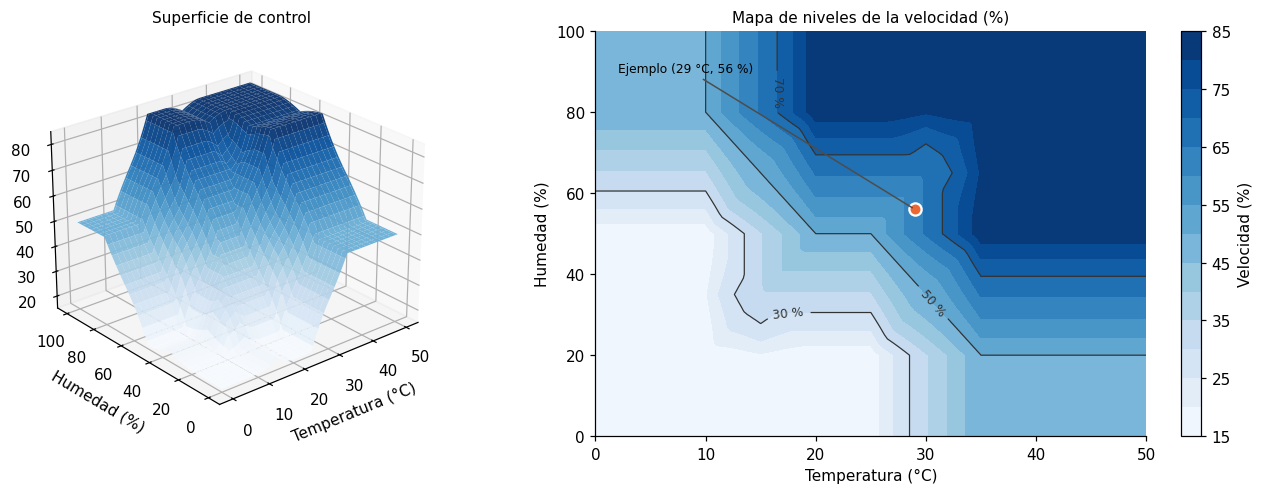

In [11]:
ts = np.arange(0, 50.5, 0.5)
hs = np.arange(0, 101, 1)
V = np.array([[mamdani(t, h)["velocidad"] for t in ts] for h in hs])

fig = plt.figure(figsize=(13, 4.6))
ax3d = fig.add_subplot(1, 2, 1, projection="3d")
TT, HH = np.meshgrid(ts, hs)
ax3d.plot_surface(TT, HH, V, cmap="Blues", edgecolor="none", alpha=0.95)
ax3d.set_xlabel("Temperatura (°C)")
ax3d.set_ylabel("Humedad (%)")
ax3d.set_zlabel("Velocidad (%)")
ax3d.view_init(elev=25, azim=-130)
ax3d.set_title("Superficie de control", fontsize=10)

ax2 = fig.add_subplot(1, 2, 2)
mapa = ax2.contourf(ts, hs, V, levels=np.arange(15, 90, 5), cmap="Blues")
lineas = ax2.contour(ts, hs, V, levels=[30, 50, 70], colors="0.2", linewidths=0.8)
ax2.clabel(lineas, fmt="%d %%", fontsize=8)
ax2.plot(29, 56, "o", color="#eb6834", ms=8, mec="white", mew=1.5)
ax2.annotate("Ejemplo (29 °C, 56 %)", (29, 56), xytext=(2, 90), fontsize=8,
             arrowprops=dict(arrowstyle="-", color="0.3"))
ax2.set_xlabel("Temperatura (°C)")
ax2.set_ylabel("Humedad (%)")
ax2.set_title("Mapa de niveles de la velocidad (%)", fontsize=10)
fig.colorbar(mapa, ax=ax2, label="Velocidad (%)")
plt.tight_layout()
plt.show()

**Figura 3.** Superficie de control del controlador difuso y su mapa de niveles. El punto naranja es el ejemplo del seguimiento manual.

In [ ]:
dif_t = np.diff(V, axis=1)  # cambio al aumentar la temperatura
dif_h = np.diff(V, axis=0)  # cambio al aumentar la humedad
print(f"Rango de salida: {V.min():.2f} % a {V.max():.2f} %")
salto = max(np.abs(dif_t).max(), np.abs(dif_h).max())
print(f"Mayor salto entre puntos vecinos: {salto:.2f} puntos porcentuales")
for nombre, d in (("temperatura", dif_t), ("humedad", dif_h)):
    pct = 100 * (d < -1e-9).mean()
    print(f"Al subir la {nombre}: mayor disminución {-d.min():.2f} puntos, "
          f"en {pct:.1f} % de los pasos")

Rango de salida: 16.50 % a 83.50 %
Mayor salto entre puntos vecinos: 3.12 puntos porcentuales
Al subir la temperatura: mayor disminucion 0.81 puntos, en 5.6 % de los pasos
Al subir la humedad: mayor disminucion 0.55 puntos, en 9.1 % de los pasos


### 5.3 Pruebas en Wokwi

Con la simulación en ejecución, se da clic sobre el DHT22 y se ajustan los controles de temperatura y humedad a los valores de cada prueba. Cada 2.5 segundos el monitor serial muestra el seguimiento de la inferencia con el mismo formato que la sección 3.5, la pantalla LCD muestra las lecturas y la velocidad, y el brillo del LED azul cambia en proporción a la velocidad.

Para el ejemplo del seguimiento manual ($T$ = 29 °C, $H$ = 56 %, valores con los que inicia el sensor en el `diagram.json`), la salida esperada en el monitor serial es:

```text
T=29.0 C  H=56.0 %
  muT [Fria, Templada, Caliente] = [0.00, 0.60, 0.40]
  muH [Baja, Media, Alta]        = [0.00, 0.80, 0.20]
  Activacion [Baja, Media, Alta] = [0.00, 0.60, 0.40]
  Velocidad del ventilador       = 62.77 %
Publicado -> {"temperatura":29.0,"humedad":56.0,"velocidad":62.77,"activacion":{"baja":0.00,"media":0.60,"alta":0.40}}
```

Y en la pantalla LCD:

```text
T:29.0C H:56.0%
Ventilador:  63%
```

![Simulación en Wokwi](imagenes/Circuito.png)

**Figura 4.** Simulación del prototipo en Wokwi con el DHT22 ajustado a 41.3 °C y 44.5 % de humedad. La pantalla LCD muestra las lecturas y una velocidad de 76 %, el LED azul enciende con el brillo correspondiente y el monitor serial muestra el seguimiento de la inferencia que hace el ESP32.

**Comparación entre el ESP32 y Python.** Para comprobar que la conversión a Arduino es correcta, se evalúa en Python la misma lectura de la Figura 4 y se compara cada resultado intermedio con lo que reporta el monitor serial.

In [13]:
# Valores reportados por el ESP32 en el monitor serial de Wokwi (Figura 4)
esp32 = {
    "mu_t": [0.00, 0.00, 1.00],
    "mu_h": [0.18, 0.82, 0.00],
    "activacion": [0.00, 0.18, 0.82],
    "velocidad": 75.85,
}

r = mamdani(41.3, 44.5)
python = {
    "mu_t": [round(v, 2) for v in r["mu_t"].values()],
    "mu_h": [round(v, 2) for v in r["mu_h"].values()],
    "activacion": [round(v, 2) for v in r["activacion"].values()],
    "velocidad": round(r["velocidad"], 2),
}

for clave in esp32:
    estado = "coincide" if esp32[clave] == python[clave] else "DIFERENTE"
    print(f"{clave:<11} ESP32: {str(esp32[clave]):<20} Python: {str(python[clave]):<20} {estado}")

mu_t        ESP32: [0.0, 0.0, 1.0]      Python: [0.0, 0.0, 1.0]      coincide
mu_h        ESP32: [0.18, 0.82, 0.0]    Python: [0.18, 0.82, 0.0]    coincide
activacion  ESP32: [0.0, 0.18, 0.82]    Python: [0.0, 0.18, 0.82]    coincide
velocidad   ESP32: 75.85                Python: 75.85                coincide


En este caso la temperatura es completamente "caliente" ($\mu$ = 1) y la humedad es mayormente "media" (0.82) y un poco "baja" (0.18). Se disparan R7 (Caliente Y Baja, que da Media con fuerza 0.18) y R8 (Caliente Y Media, que da Alta con fuerza 0.82), y el centroide queda en 75.85 %. El ESP32 y Python dan los mismos valores en todas las etapas, así que la conversión a C++ reproduce el modelo sin cambios.

### 5.4 Prueba de la comunicación MQTT

Para representar la capa de aplicación del sistema IoT se usa el cliente web de HiveMQ (https://www.hivemq.com/demos/websocket-client/), un cliente MQTT que funciona en el navegador. Con él se reciben en tiempo real los mensajes que publica el ESP32, como lo haría un dashboard o una aplicación móvil.

**Procedimiento**

1. Iniciar la simulación en Wokwi y verificar en el monitor serial los mensajes `WiFi conectado`, `Conectando a MQTT... conectado` y `Publicado -> {...}`.
2. En la sección **Connection** del cliente web, capturar los datos de la tabla siguiente y presionar **Connect**. El indicador de estado cambia a *connected*.
3. En **Subscriptions**, presionar **Add New Topic Subscription**, escribir el tópico `mshp/iot/p22/telemetria` con QoS 0 y presionar **Subscribe**.
4. Observar en **Messages** la telemetría recibida y compararla con el monitor serial de Wokwi.
5. Cambiar los valores del DHT22 en Wokwi y comprobar que el siguiente mensaje refleja las nuevas lecturas y la nueva velocidad.

| Campo | Valor | Explicación |
|---|---|---|
| Host | `broker.hivemq.com` | Broker MQTT público, el mismo que usa el ESP32 |
| Port | `8884` | Puerto de MQTT sobre WebSockets seguros |
| ClientID | Valor generado automáticamente | Identificador único del cliente ante el broker |
| Username / Password | Vacíos | El broker público no requiere autenticación |
| SSL | Activado | Necesario para el puerto 8884 |

![Cliente web de HiveMQ](imagenes/HiveMQ.png)

**Figura 5.** Cliente web de HiveMQ conectado al broker y suscrito al tópico `mshp/iot/p22/telemetria`. Los mensajes recibidos contienen la temperatura, la humedad, la velocidad calculada por el controlador difuso y la activación de cada conjunto de salida, y son idénticos a la línea `Publicado ->` del monitor serial de la Figura 4.

**Resultados**

| Prueba | Resultado esperado | Resultado obtenido |
|---|---|---|
| Conexión del ESP32 al broker | El monitor serial muestra `Conectando a MQTT... conectado` | Correcto |
| Conexión del cliente web | El indicador cambia a *connected* | Correcto (Figura 5) |
| Recepción de la telemetría | Llega un mensaje JSON en el tópico `mshp/iot/p22/telemetria` | Correcto (Figura 5) |
| Integridad del mensaje | El JSON recibido es idéntico al publicado por el ESP32 | Correcto: 41.3 °C, 44.5 %, velocidad 75.85 % y activación (0.00, 0.18, 0.82) en ambos |
| Decisión explicable a distancia | El mensaje incluye la activación de cada conjunto de salida | Correcto: desde la nube se ve que domina "velocidad alta" (0.82) |

En la Figura 5 los mensajes llegan cada 7 a 10 segundos de reloj, aunque el programa publica cada 2.5 s. La diferencia se debe a que Wokwi no siempre simula en tiempo real: el indicador de la Figura 4 muestra que la simulación corría al 42 % de la velocidad real, así que 2.5 s simulados equivalen a unos 6 s reales, más la latencia de la red. En un ESP32 físico el intervalo sería de 2.5 s.

## 6. Evaluación

**Funcionamiento del modelo.** El seguimiento manual y el programa coinciden en todas las etapas: los grados de pertenencia, las fuerzas de disparo de las cuatro reglas activas, la activación de cada conjunto de salida y la forma del conjunto agregado. El centroide calculado a mano (62.65 %) coincide con la integral numérica, y la versión discreta que se ejecuta en el microcontrolador da 62.77 %. Esto confirma que la implementación sigue fielmente el método Mamdani.

**Conversión a Arduino y comunicación IoT.** En la simulación en Wokwi, el ESP32 calculó para 41.3 °C y 44.5 % los mismos grados de pertenencia, activaciones y velocidad (75.85 %) que Python, por lo que la traducción a C++ es fiel al modelo. La telemetría publicada por MQTT llegó sin alteraciones al cliente web de HiveMQ, lo que cierra el ciclo sensor, decisión en el borde, actuador y nube.

**Comportamiento del controlador.** Los casos de prueba responden al criterio de diseño: la velocidad aumenta con la temperatura y con la humedad, los casos intermedios (frío húmedo y calor seco) dan velocidad media, y las lecturas fuera de rango se saturan correctamente (P10 da lo mismo que T = 0 °C y H = 100 %). La superficie de control es continua: no hay saltos como el del control por umbral de la Práctica 1.2, de modo que pequeñas variaciones en la lectura del sensor producen pequeñas variaciones en el ventilador.

**Observaciones del análisis de la superficie.**

- **La salida no llega a 0 % ni a 100 %.** El centroide de un conjunto siempre queda dentro de su área: con solo la regla "velocidad baja" activa al máximo, el centroide del triángulo (0, 0, 50) está en 16.5 %, y simétricamente el máximo es 83.5 %. Es una propiedad conocida de la defuzzificación por centroide. Si se necesita apagar el ventilador, se puede extender el universo de salida más allá de 0 a 100 (y saturar después), agregar un conjunto "Apagado" o aplicar un umbral sobre la salida.
- **Pequeñas zonas no monótonas.** El análisis de la superficie muestra que en algunos pasos la velocidad disminuye ligeramente al aumentar una entrada (la magnitud aparece en la salida de la sección 5.2, del orden de un punto porcentual). Ocurre porque al recortar con el mínimo y unir con el máximo, el área de un conjunto que pierde activación cambia de forma no lineal y desplaza el centroide. En la práctica es imperceptible para un ventilador, pero si se requiere monotonía estricta se puede usar implicación por producto y agregación por suma, o un modelo Sugeno.

**Ventajas observadas de la lógica difusa en IoT.**

- El conocimiento del sistema está en nueve reglas legibles; modificar el comportamiento no requiere reentrenar nada, solo cambiar una celda de la tabla.
- La inferencia es ligera y se ejecuta en el propio ESP32, por lo que el dispositivo es autónomo y reacciona aunque no haya conexión.
- La telemetría incluye la activación de cada conjunto, lo que permite explicar a distancia por qué el dispositivo tomó cada decisión.

**Limitaciones y mejoras posibles.**

- Las funciones de pertenencia se ajustaron con criterio propio; en una aplicación real se calibrarían con mediciones del lugar o con un método de aprendizaje (por ejemplo, un sistema neuro-difuso ANFIS).
- Se podría agregar una tercera entrada (por ejemplo, la tasa de cambio de la temperatura) para anticiparse al calentamiento, a costa de aumentar el número de reglas.
- El broker público no tiene autenticación ni cifrado; en producción se usaría un broker privado con TLS.

## 7. Conclusiones

El modelo de inferencia Mamdani permite trasladar a un programa el razonamiento de una persona expresado con palabras. Al analizar sus cuatro etapas se ve que cada una es una operación sencilla: la fuzzificación evalúa funciones lineales por tramos, las reglas se combinan con mínimos y máximos, y la defuzzificación es un promedio ponderado. Esta sencillez es la que lo hace adecuado para dispositivos con pocos recursos.

El seguimiento manual del ejemplo de 29 °C y 56 % de humedad mostró en detalle cómo una lectura pertenece parcialmente a varios conjuntos, cómo varias reglas se disparan a la vez con distinta fuerza, cómo se resuelve con el máximo que tres reglas concluyan lo mismo y cómo el centroide combina las conclusiones en una velocidad de aproximadamente 63 %. Que los cálculos a mano coincidan con el programa confirma que la implementación es correcta.

Desarrollar primero el modelo en Python facilitó probarlo, graficarlo y analizar su superficie de control antes de pasar al hardware. Al haberlo escrito con estructuras simples, su conversión a C++ fue directa, y el ESP32 en Wokwi ejecuta exactamente el mismo modelo. El resultado es un ejemplo de IA aplicada al IoT en el borde: el dispositivo percibe su entorno, decide de forma autónoma con un modelo de razonamiento aproximado, actúa de manera gradual y comunica tanto sus datos como su decisión a la nube.

## Referencias

- Arduino. (s.f.). *Arduino Documentation*. https://docs.arduino.cc/
- Espressif Systems. (s.f.). *Arduino core for the ESP32*. https://docs.espressif.com/projects/arduino-esp32/
- Hernández Parada, M. S. (2026). *Análisis, implementación y prueba de un modelo de lógica difusa Mamdani para comprender el funcionamiento de IA aplicada al IOT* [Repositorio de GitHub]. GitHub. [Ver en GitHub](https://github.com/RKCbas/LENGUAJES-DE-CIENCIA-DE-DATOS-B-SICO---PRACTICAS/blob/main/Cuatrimestre%204/9%20-%20T%C3%B3picos%20de%20IA%20para%20la%20transformaci%C3%B3n%20digital/Practica%202.2/An%C3%A1lisis%2C%20implementaci%C3%B3n%20y%20prueba%20de%20un%20modelo%20de%20l%C3%B3gica%20difusa%20Mamdani%20para%20comprender%20el%20funcionamiento%20de%20IA%20aplicada%20al%20IOT.ipynb)
- HiveMQ. (s.f.). *MQTT Essentials*. https://www.hivemq.com/mqtt/
- Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering, 9*(3), 90-95. https://doi.org/10.1109/MCSE.2007.55
- Jang, J.-S. R., Sun, C.-T. y Mizutani, E. (1997). *Neuro-Fuzzy and Soft Computing: A Computational Approach to Learning and Machine Intelligence*. Prentice Hall.
- Mamdani, E. H. y Assilian, S. (1975). An experiment in linguistic synthesis with a fuzzy logic controller. *International Journal of Man-Machine Studies, 7*(1), 1-13. https://doi.org/10.1016/S0020-7373(75)80002-2
- Ross, T. J. (2010). *Fuzzy Logic with Engineering Applications* (3a ed.). Wiley.
- Wokwi. (s.f.). *Wokwi Documentation*. https://docs.wokwi.com/
- Zadeh, L. A. (1965). Fuzzy sets. *Information and Control, 8*(3), 338-353. https://doi.org/10.1016/S0019-9958(65)90241-X